# 06a · Simulação do CD (SimPy): modelo, validação e calibração
**Por que simular?** As análises das fases 4 e 5 olham médias. Gargalo, porém, é fila: dois
caminhões que chegam juntos esperam, mesmo que a doca fique ociosa o resto do dia. A simulação de
eventos discretos reproduz o CD minuto a minuto, com recursos limitados (docas, retráteis,
separadores), e permite testar decisões **antes** de gastar: mais uma doca? menos empilhadeiras?
Quantos temporários no Natal?

**O modelo** (`src/flowsim.py`):

| Fluxo | Etapas | Recursos disputados |
|---|---|---|
| Recebimento (dia) | caminhão chega → espera doca → setup 15 min → descarga palete a palete → putaway | docas e retráteis por zona |
| Separação (noite, 18h–2h) | pedido elegível (e-commerce: corte 15h) → espera o turno → separador pega o pedido → linhas sem face pedem a retrátil | separadores e retráteis da noite por zona |

Tempos de `config/parameters.yaml` e `config/data_generation.yaml`; tempo de cada pedido calculado
com o slotting da Fase 5 (distância da face, fração atendida pela face, descidas do pulmão).
Entradas = **caminhões e pedidos reais** dos dados.

*EN summary: discrete-event model of receiving and night picking; validated on the real 10%-scale
trace (dock-to-stock) and calibrated at full scale against the observed order queue by month.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowsim as fs
from dcanalysis import q, save, savefig, log, ROOT

NB = "06a"
PH6 = ROOT / "reports" / "phase6"
prm = fs.carregar_parametros()
slot = fs.carregar_slotting()
INI, FIM, MEDIR = "2025-09-24", "2026-02-01", "2025-10-01"   # 1 semana de aquecimento
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

## 1. Validação do recebimento com os caminhões reais (escala 10%)
Rodamos o modelo com **exatamente** os caminhões registrados e os recursos que os dados mostram em
escala 10% (2 docas no seco, 1 no resfriado, 1 no congelado; 1 retrátil por doca). Se o modelo
estiver certo, o dock-to-stock simulado deve ficar perto do observado.

In [2]:
cam10 = fs.preparar_caminhoes(INI, FIM)
sub_vazio = fs.preparar_pedidos(INI, INI, slot, prm)        # sem pedidos: só o recebimento
cd10 = fs.CD(prm, INI, docks={"dry": 2, "chilled": 1, "frozen": 1},
             forklifts={"dry": 2, "chilled": 1, "frozen": 1}, pickers={z: 0 for z in fs.ZONAS})
res10 = cd10.rodar(cam10, sub_vazio, FIM)
pal10, _, rec10 = fs.indicadores(res10, prm, INI, MEDIR)

obs = q("""SELECT zone, dock_to_stock_min AS d2s, dock_exposure_min AS exp
           FROM fact_receipt WHERE status = 'ACCEPTED' AND arrival_ts >= :i AND arrival_ts < :f""",
        i=MEDIR, f=FIM)
valid = pd.DataFrame({
    "d2s_mediana_obs": obs.groupby("zone").d2s.median(), "d2s_mediana_sim": rec10.d2s_mediana,
    "d2s_p90_obs": obs.groupby("zone").d2s.quantile(0.9), "d2s_p90_sim": rec10.d2s_p90,
    "exposicao_media_obs": obs.groupby("zone").exp.mean(), "exposicao_media_sim": rec10.exposicao_media})
save(valid.reset_index(names="zona").round(1), "06a_validacao_recebimento", out=PH6)
valid.round(1)

,d2s_mediana_obs,d2s_mediana_sim,d2s_p90_obs,d2s_p90_sim,exposicao_media_obs,exposicao_media_sim
zone,,,,,,
chilled,74.9,67.3,159.6,141.9,27.7,14.7
dry,52.4,47.6,146.3,111.6,NaN,11.8
frozen,65.0,51.0,144.1,101.6,35.6,9.6


**Leitura:**
- A **mediana** do dock-to-stock simulado fica a 5–14 min da real nas três zonas: o modelo de
  docas + descarga + putaway representa bem o recebimento típico. O **p90** simulado é 10–30% menor,
  porque o real tem variabilidade que o modelo não inclui (interrupções, conferência demorada,
  caminhão com problema). Os cenários devem ser lidos como **comparação**, não como previsão exata.
- A **exposição na doca** observada (palete parado entre a descarga e a guarda) é **2–4× maior**
  que a simulada. Com os recursos que existem, o palete frio deveria esperar ~10–15 min; os
  25–35 min reais **não se explicam por falta de empilhadeira**. A causa é de processo (conferência,
  etiquetagem, palete aguardando liberação da qualidade). É um achado importante: comprar retrátil
  não resolveria a quebra de frio na doca (Fase 4). Resolve-se com padrão de trabalho (POP da Fase 9).

## 2. Escala cheia e calibração da separação
Para os cenários usamos a **escala cheia** (o CD real): cada caminhão e cada pedido dos dados vira 10
cópias com horário levemente deslocado (±30 min). Isso preserva dias, horários e mix e multiplica o
volume. Docas e retráteis do dia vêm do projeto (16/4/4 docas; 16/9/7 retráteis).

**Separadores e retráteis da noite** não constam dos dados. Calibramos esses dois valores para que a
fila de pedidos simulada reproduza a observada mês a mês. O dimensionamento ficou em 1,3× a
necessidade média de outubro (premissa em `config/parameters.yaml`).

In [3]:
base, pal, ped, rec, uso = fs.rodar_cenario("Base", prm, slot, INI, FIM, MEDIR)
obs_fila = q("""SELECT substr(order_date, 1, 7) AS mes,
                       AVG(julianday(release_date) - julianday(order_date)) AS fila_obs
                FROM (SELECT order_id, MIN(order_date) AS order_date, MIN(release_date) AS release_date
                      FROM fact_order_line GROUP BY order_id)
                WHERE order_date >= :i AND order_date < :f GROUP BY 1""", i=MEDIR, f=FIM)
cal = obs_fila.merge(ped.groupby("mes").fila_dias.mean().rename("fila_sim").reset_index(), on="mes")
save(cal.round(2), "06a_calibracao_fila", out=PH6)
print("Separadores por turno:", prm["pickers"], "| retráteis da noite:", prm["forklifts_night"])
cal.round(2)

Separadores por turno: {'dry': 68, 'chilled': 17, 'frozen': 11} | retráteis da noite: {'dry': 29, 'chilled': 5, 'frozen': 4}


,mes,fila_obs,fila_sim
0,2025-10,0.26,0.26
1,2025-11,0.38,0.33
2,2025-12,1.33,1.45
3,2026-01,1.12,0.58


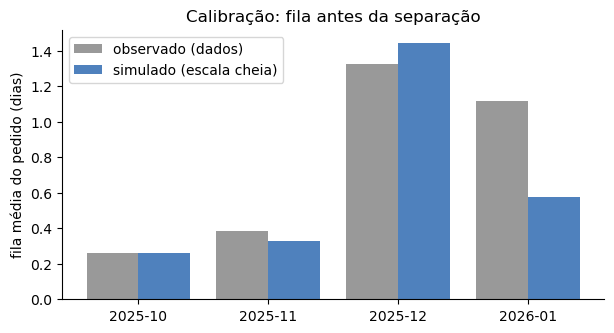

In [4]:
# Colunas agrupadas: observado × simulado por mês (poucos períodos, comparação direta de valores).
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(cal))
ax.bar(x - 0.2, cal.fila_obs, 0.4, label="observado (dados)", color="#999999")
ax.bar(x + 0.2, cal.fila_sim, 0.4, label="simulado (escala cheia)", color="#4F81BD")
ax.set_xticks(x, cal.mes); ax.set_ylabel("fila média do pedido (dias)")
ax.set_title("Calibração: fila antes da separação"); ax.legend()
savefig(fig, "06a_calibracao_fila", out=PH6)

**Leitura:** o modelo reproduz o comportamento real: fila de ~0,3 dia em meses normais (efeito do
corte das 15h do e-commerce) que **explode em dezembro**. Em janeiro a fila simulada é menor que a
real: o modelo não inclui a falha de frio de jan/2026 nem as faltas de pessoal do período
(limitação conhecida).

## 3. O que a linha de base já mostra

In [5]:
horas_turno = prm["shift_hours"] / 24
util = pd.DataFrame({
    "docas (24h)": {z: uso[f"doca_{z}"] for z in fs.ZONAS},
    "retráteis do dia (24h)": {z: uso[f"retratil_{z}"] for z in fs.ZONAS},
    "retráteis da noite (no turno)": {z: uso[f"retratil_noite_{z}"] / horas_turno for z in fs.ZONAS}})
print("Utilização média dos recursos (fração do tempo ocupado):")
print((100 * util).round(0))
rec[["caminhoes", "espera_doca_media", "espera_doca_p90", "d2s_mediana", "d2s_p90"]].round(0)

Utilização média dos recursos (fração do tempo ocupado):
         docas (24h)  retráteis do dia (24h)  retráteis da noite (no turno)
dry             18.0                    17.0                           72.0
chilled         37.0                    15.0                           74.0
frozen          23.0                    11.0                           62.0


,caminhoes,espera_doca_media,espera_doca_p90,d2s_mediana,d2s_p90
zone,,,,,
chilled,4610,136.0,348.0,150.0,426.0
dry,11010,15.0,53.0,50.0,136.0
frozen,3200,66.0,169.0,103.0,257.0


**Leitura:**
- **Docas frias:** com 4 docas no resfriado e 4 no congelado (projeto da Fase 1), o caminhão frio
  espera em média **~2 h no pátio** (resfriado) e o p90 passa de 5 h. A utilização média das docas
  parece baixa (24 h), mas as chegadas se concentram entre 7h e 12h (Fase 4). **A doca fria é o
  gargalo do recebimento em escala cheia**, e o seco (16 docas) folga. Isso é testado na 06b.
- **Separação pelo pulmão:** para reproduzir o nível de serviço dos dados, o turno da noite precisa
  de **~29 retráteis só no seco**, porque 60% das linhas de caixa saem dos níveis 2–6. É uma frota
  cara, e a Fase 5 (slotting) ataca exatamente isso.

In [6]:
save(pd.DataFrame([base]).round(3), "06a_base", out=PH6)
log(NB, "simulação SimPy validada na escala 10% (caminhões reais, dock-to-stock) e calibrada em escala "
        "cheia (bootstrap x10; separadores e retráteis da noite = 1,3x necessidade de out/2025)")